# EUR/USD Volatility Modeling with ARIMA-GARCH

## 1. Data and log-returns

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.data import download_fred, load_prices, log_returns

download_fred()

Snapshot already exists: data/raw/DEXUSEU.csv


In [2]:
prices = load_prices()
returns = log_returns(prices)

print(f"Period: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"Number of prices: {len(prices)} | Number of returns: {len(returns)}")
print(f"Price range: {prices.min():.4f} -> {prices.max():.4f}")
print(returns.describe().round(4))

# Sanity checks
assert prices.index.is_monotonic_increasing
assert prices.notna().all() and (prices > 0).all()
assert len(returns) == len(prices) - 1

# Log-returns add up: their sum equals the log-return over the full period
print(f"Sum of daily log-returns: {returns.sum():.4f}")
print(f"Full-period log-return:  {100 * np.log(prices.iloc[-1] / prices.iloc[0]):.4f}")

# Daily and yearly volatility
sigma_day = returns.std()
print(f"Daily vol: {sigma_day:.3f}% | Yearly vol: {np.sqrt(252) * sigma_day:.2f}%")

Period: 2011-01-03 -> 2025-12-31
Number of prices: 3751 | Number of returns: 3750
Price range: 0.9616 -> 1.4875
count    3750.0000
mean       -0.0035
std         0.5109
min        -2.6724
25%        -0.2760
50%         0.0000
75%         0.2729
max         3.0643
Name: log_return, dtype: float64
Sum of daily log-returns: -13.0427
Full-period log-return:  -13.0427
Daily vol: 0.511% | Yearly vol: 8.11%


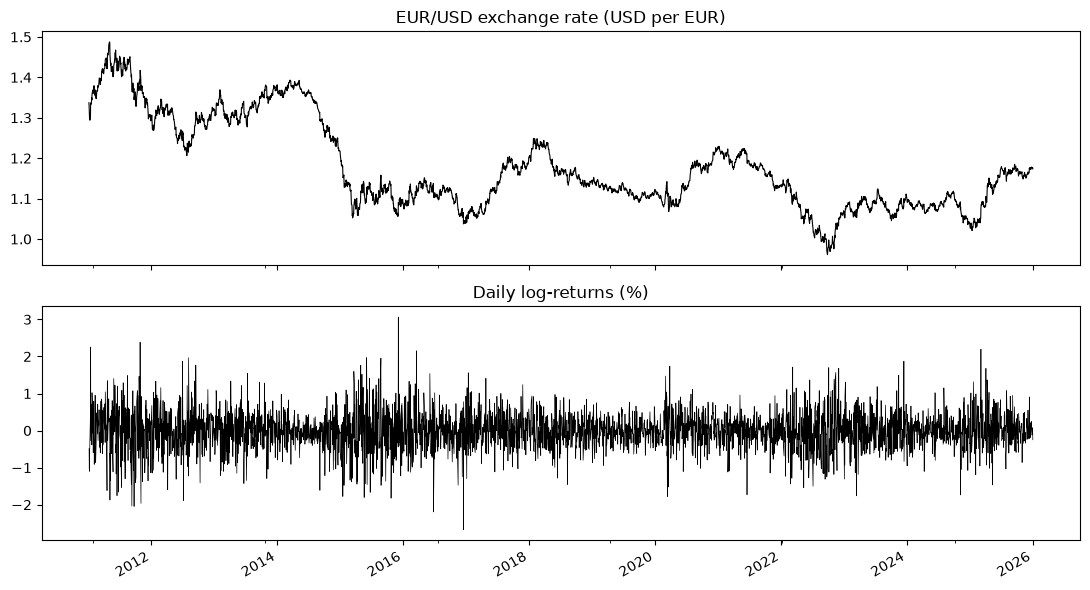

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

prices.plot(ax=axes[0], color="black", lw=0.8)
axes[0].set_title("EUR/USD exchange rate (USD per EUR)")
axes[0].set_xlabel("")

returns.plot(ax=axes[1], color="black", lw=0.5)
axes[1].set_title("Daily log-returns (%)")
axes[1].set_xlabel("")

plt.tight_layout()
fig.savefig("figures/01_prices_returns.png", dpi=150)
plt.show()

## 2. Stylized facts and stationarity

In [4]:
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

from src.evaluation import distribution_summary, ljung_box, stationarity_tests


In [5]:
print(distribution_summary(returns).round(4))

mean                -0.0035
std                  0.5109
skewness             0.0089
excess_kurtosis      2.0486
jarque_bera        655.7647
jb_pvalue            0.0000
dtype: float64


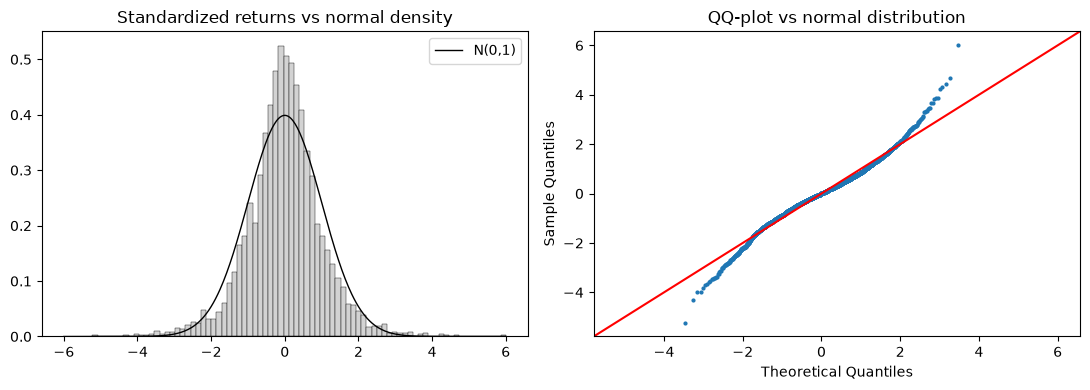

In [6]:
z = (returns - returns.mean()) / returns.std()  # standardized returns

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

grid = np.linspace(-6, 6, 400)
axes[0].hist(z, bins=80, density=True, color="lightgray", edgecolor="black", lw=0.3)
axes[0].plot(grid, stats.norm.pdf(grid), color="black", lw=1, label="N(0,1)")
axes[0].set_title("Standardized returns vs normal density")
axes[0].legend()

sm.qqplot(z, line="45", ax=axes[1], markersize=2)
axes[1].set_title("QQ-plot vs normal distribution")

plt.tight_layout()
fig.savefig("figures/02_distribution.png", dpi=150)
plt.show()

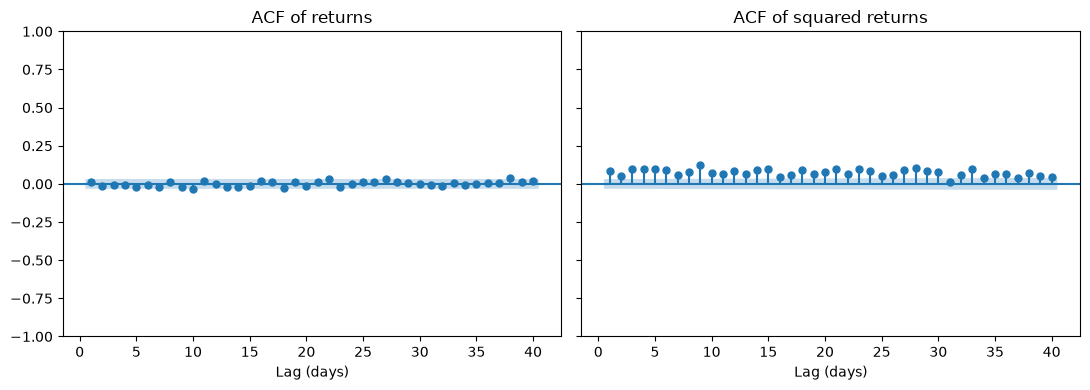

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

plot_acf(returns, lags=40, zero=False, ax=axes[0], title="ACF of returns")
plot_acf(returns**2, lags=40, zero=False, ax=axes[1], title="ACF of squared returns")

for ax in axes:
    ax.set_xlabel("Lag (days)")

plt.tight_layout()
fig.savefig("figures/03_acf.png", dpi=150)
plt.show()

In [8]:
lb = pd.concat({
    "returns": ljung_box(returns),
    "squared returns": ljung_box(returns**2),
})
print(lb.round(4))

                     lb_stat  lb_pvalue
returns         10   10.5832     0.3909
                20   20.6686     0.4169
squared returns 10  294.7418     0.0000
                20  504.7010     0.0000


In [9]:
log_prices = np.log(prices)

stationarity = pd.DataFrame({
    "log price": stationarity_tests(log_prices),
    "log-return": stationarity_tests(returns),
}).T
print(stationarity.round(4))

            adf_stat  adf_pvalue  kpss_stat  kpss_pvalue
log price    -2.0485      0.2657     5.4188         0.01
log-return  -60.4222      0.0000     0.0980         0.10


## 3. Mean model: ARIMA vs random walk

In [10]:
from statsmodels.tsa.arima.model import ARIMA
from src.models import arima_order_selection, one_step_forecasts

y = returns.to_numpy()
ic = arima_order_selection(y)

delta = ic - ic.loc[(0, 0)]  # difference with the random walk model
print(delta.round(2))
print("Best by AIC:", ic["aic"].idxmin(), "| Best by BIC:", ic["bic"].idxmin())

      aic    bic
p q             
0 0  0.00   0.00
  1  1.34   7.57
  2  2.79  15.25
  3  4.57  23.26
1 0  1.36   7.59
  1  3.09  15.55
  2  1.71  20.40
  3  3.65  28.57
2 0  2.78  15.24
  1  1.69  20.37
  2  0.48  25.40
  3  5.59  36.74
3 0  4.60  23.29
  1  6.60  31.52
  2  5.59  36.74
  3  7.59  44.97
Best by AIC: (np.int64(0), np.int64(0)) | Best by BIC: (np.int64(0), np.int64(0))


In [11]:
p_best, q_best = ic["aic"].idxmin()
res_best = ARIMA(y, order=(p_best, 0, q_best), trend="c").fit()
print(res_best.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0035      0.008     -0.418      0.676      -0.020       0.013
sigma2         0.2609      0.004     61.606      0.000       0.253       0.269


In [12]:
train_size = int(0.8 * len(y))
test = y[train_size:]
print(f"Test period: {returns.index[train_size].date()} -> {returns.index[-1].date()} ({len(test)} days)")

forecasts = {
    "random walk": np.zeros_like(test),
    "constant mean": np.full_like(test, y[:train_size].mean()),
}
for order in {(p_best, q_best), (1, 1)} - {(0, 0)}:
    forecasts[f"ARMA{order}"] = one_step_forecasts(y, (order[0], 0, order[1]), train_size)

rmse = pd.Series({name: np.sqrt(np.mean((test - f) ** 2)) for name, f in forecasts.items()})
print(pd.DataFrame({"RMSE": rmse, "ratio vs random walk": rmse / rmse["random walk"]}).round(5))

Test period: 2023-01-03 -> 2025-12-31 (750 days)
                  RMSE  ratio vs random walk
random walk    0.45404               1.00000
constant mean  0.45431               1.00058
ARMA(1, 1)     0.45458               1.00118


## 4. Variance models: GARCH, GJR-GARCH, EGARCH

In [13]:
from src.models import GARCH_SPECS, fit_garch, persistence, half_life
from src.evaluation import residual_diagnostics

results, rows = {}, []
for model in GARCH_SPECS:
    for dist in ["normal", "t"]:
        res = fit_garch(returns, model, dist)
        results[(model, dist)] = res
        pers = persistence(res, model)
        rows.append({
            "model": model, "dist": dist,
            "loglik": res.loglikelihood, "aic": res.aic, "bic": res.bic,
            "persistence": pers, "half_life_days": half_life(pers),
            "gamma": res.params.get("gamma[1]", np.nan),
            "gamma_pvalue": res.pvalues.get("gamma[1]", np.nan),
            "nu": res.params.get("nu", np.nan),
        })

garch_table = pd.DataFrame(rows).set_index(["model", "dist"])
print(garch_table.round(4))

                     loglik        aic        bic  persistence  \
model     dist                                                   
GARCH     normal -2562.9887  5133.9774  5158.8954       0.9934   
          t      -2484.9383  4979.8766  5011.0242       0.9972   
GJR-GARCH normal -2560.6965  5131.3930  5162.5405       0.9943   
          t      -2482.4685  4976.9371  5014.3142       0.9979   
EGARCH    normal -2558.9021  5127.8042  5158.9518       0.9932   
          t      -2483.3777  4978.7554  5016.1324       0.9962   

                  half_life_days   gamma  gamma_pvalue      nu  
model     dist                                                  
GARCH     normal        105.0657     NaN           NaN     NaN  
          t             244.6289     NaN           NaN  6.8419  
GJR-GARCH normal        121.4851  0.0150        0.0878     NaN  
          t             325.2441  0.0183        0.0188  6.8291  
EGARCH    normal        100.9737 -0.0183        0.0432     NaN  
          t     

In [14]:
res = results[("GARCH", "t")]
print(pd.DataFrame({"coef": res.params, "p-value": res.pvalues}).round(4))

p = res.params
long_run_vol = np.sqrt(p["omega"] / (1 - p["alpha[1]"] - p["beta[1]"]))
print(f"Long-run daily vol: {long_run_vol:.3f}% (sample std: {returns.std():.3f}%)")

            coef  p-value
mu       -0.0045   0.5014
omega     0.0009   0.0502
alpha[1]  0.0384   0.0000
beta[1]   0.9587   0.0000
nu        6.8419   0.0000
Long-run daily vol: 0.570% (sample std: 0.511%)


In [15]:
z_raw = (returns - returns.mean()) / returns.std()  # no model: constant volatility

diag = {"no model (constant vol)": residual_diagnostics(z_raw)}
for key, res in results.items():
    diag[f"{key[0]}-{key[1]}"] = residual_diagnostics(res.std_resid)

print(pd.DataFrame(diag).T.round(4))

                         lb_z_pvalue  lb_z2_pvalue  arch_lm_pvalue  \
no model (constant vol)       0.3909        0.0000          0.0000   
GARCH-normal                  0.6586        0.9443          0.9569   
GARCH-t                       0.6551        0.9672          0.9750   
GJR-GARCH-normal              0.6304        0.9329          0.9449   
GJR-GARCH-t                   0.6210        0.9502          0.9584   
EGARCH-normal                 0.5927        0.8298          0.8483   
EGARCH-t                      0.5765        0.7911          0.8100   

                         excess_kurtosis  
no model (constant vol)           2.0486  
GARCH-normal                      1.7113  
GARCH-t                           1.8613  
GJR-GARCH-normal                  1.6999  
GJR-GARCH-t                       1.8513  
EGARCH-normal                     1.6206  
EGARCH-t                          1.7084  


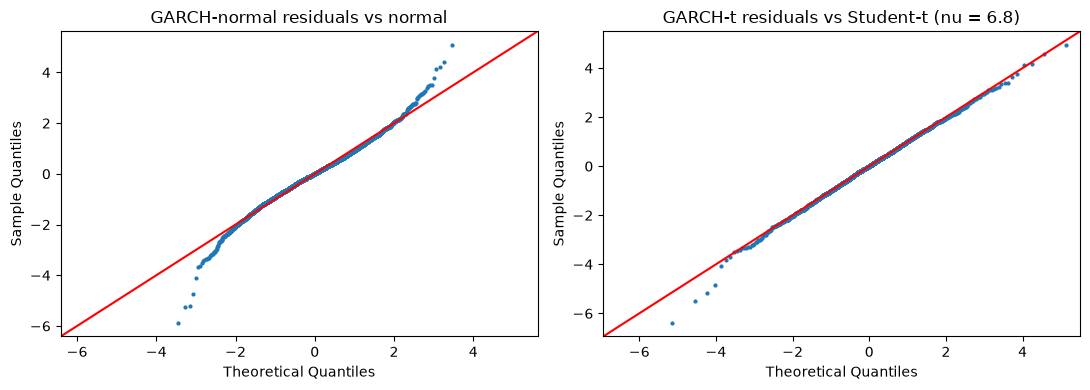

In [16]:
z_n = results[("GARCH", "normal")].std_resid
z_t = results[("GARCH", "t")].std_resid
nu = results[("GARCH", "t")].params["nu"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(z_n, line="45", ax=axes[0], markersize=2)
axes[0].set_title("GARCH-normal residuals vs normal")
sm.qqplot(z_t, dist=stats.t, distargs=(nu,), scale=np.sqrt((nu - 2) / nu),
          line="45", ax=axes[1], markersize=2)
axes[1].set_title(f"GARCH-t residuals vs Student-t (nu = {nu:.1f})")
plt.tight_layout()
fig.savefig("figures/04_qq_residuals.png", dpi=150)
plt.show()

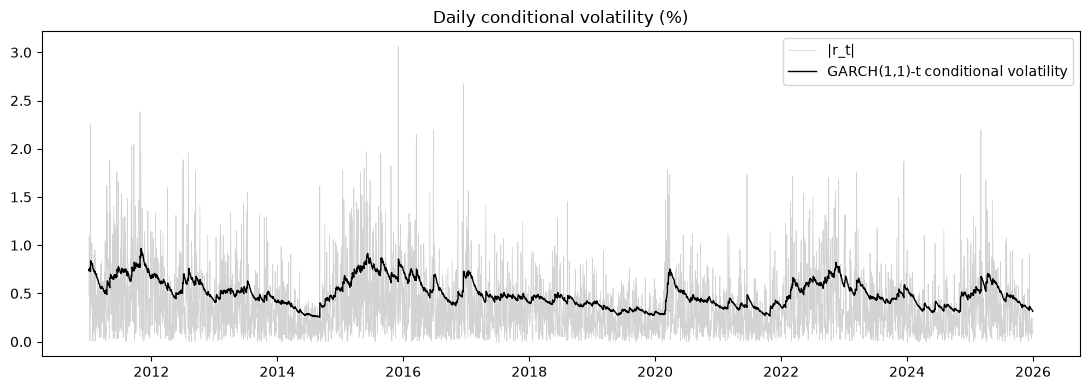

In [17]:
sigma = results[("GARCH", "t")].conditional_volatility

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(returns.abs(), color="lightgray", lw=0.5, label="|r_t|")
ax.plot(sigma, color="black", lw=1, label="GARCH(1,1)-t conditional volatility")
ax.set_title("Daily conditional volatility (%)")
ax.legend()
plt.tight_layout()
fig.savefig("figures/05_conditional_vol.png", dpi=150)
plt.show()